# Preprocesamiento de datos de texto

## 🗺️ Mapa de este notebook

Este notebook alterna **teoría** (cajas 📘) y **práctica** (código, incluyendo celdas de práctica 🧪). El recorrido:

1. **Motivación y glosario** — por qué preprocesar y el vocabulario básico
2. **Normalización** — llevar el texto a una forma canónica
3. **Tokenización** — separar por espacios, con reglas, y con algoritmos modernos (BPE, WordPiece)
4. **Lematización y stemming** — reducir palabras a su forma base
5. **Errores comunes** — lo que no hay que hacer

Trabajaremos con un corpus de **noticias en español** (XL-Sum). Ejecuta las celdas en orden.


> ## 📘 Pre-procesamiento de Texto — ¿Por qué empezamos por aquí?
>
> *Curso: Pre-procesamiento y Exploración de Texto — Andrés Abeliuk, Fabrizzio Pezzolla*
>
> ### 🎯 La idea en una frase
>
> > [**El 80% del tiempo en un proyecto de NLP se va en preprocesar los datos.**](https://www.refontelearning.com/blog/data-science-ai-in-2026-top-trends-essential-skills-and-career-strategies)
>
> Suena exagerado, pero es la experiencia de casi todo el que ha trabajado con texto real. Antes de entrenar cualquier modelo, hay que **limpiar, ordenar y estandarizar** el texto. Este notebook es exactamente sobre eso.
>
> ### 🤔 ¿Por qué es necesario?
>
> El texto "en bruto" que sacamos de internet, de un formulario o de un documento está lleno de **ruido**: mayúsculas inconsistentes, tildes que a veces están y a veces no, emojis, signos de puntuación, palabras que no aportan nada ("el", "de", "y")... Todo eso confunde a los algoritmos, que en el fondo solo ven secuencias de caracteres.
>
> 💡 **Analogía:** preprocesar texto es como lavar y cortar las verduras antes de cocinar. No es la parte glamorosa, pero sin ella no hay plato.
>
> ### 🧰 ¿Qué vamos a hacer con el texto?
>
> Los cuatro grandes objetivos del preprocesamiento, que iremos viendo uno a uno en este notebook:
>
> 1. **Normalización** — homogeneizar formatos: pasar a minúsculas, quitar tildes, unificar variantes.
> 2. **Tokenización** — dividir el texto en unidades con significado (palabras, subpalabras u oraciones).
> 3. **Eliminación de ruido** — quitar palabras irrelevantes (*stopwords*), puntuación y caracteres especiales.
> 4. **Lematización o stemming** — reducir cada palabra a su forma base o raíz, para que "corriendo", "corrí" y "correremos" cuenten como lo mismo.
>
> ### 📖 Glosario básico (lo usaremos todo el curso)
>
> <table><thead><tr><th>Término</th><th>Qué significa</th></tr></thead><tbody><tr><td><b>Token</b></td><td>La unidad mínima de análisis. Casi siempre es una palabra, pero puede ser una subpalabra o un símbolo.</td></tr><tr><td><b>Vocabulario</b></td><td>El conjunto de todos los tokens <i>distintos</i> que aparecen en un corpus.</td></tr><tr><td><b>Documento</b></td><td>Una instancia de texto: una noticia, un chiste, un tweet, una sospecha diagnóstica...</td></tr><tr><td><b>Corpus</b></td><td>Un conjunto de documentos. Es nuestro "dataset" de texto.</td></tr><tr><td><b>Corpora</b></td><td>El plural de corpus. Sí, es latín.</td></tr></tbody></table>
>
> ⚠️ **Ojo con esto:** cada paso de preprocesamiento que apliques al entrenar un modelo **debes replicarlo exactamente igual** cuando el modelo esté en producción. Si entrenas con texto en minúsculas sin tildes, en producción el texto también tiene que llegar así. Por eso conviene tener el preprocesamiento bien empaquetado y controlado.


In [ ]:
# --- Instalación de las librerías que Colab NO trae preinstaladas ---
# Importante: no usamos `-U` sobre numpy/pandas/datasets/etc.; actualizarlos en caliente
# rompe el entorno de Colab (ImportError de numpy). Si ves ese error: Entorno de ejecución -> Reiniciar sesión.
!pip install -q tokenizers nltk
!python -m spacy download es_core_news_sm -q   # Modelo de spaCy en español


In [ ]:
import datasets  # Biblioteca de manejo de conjuntos de datos para procesamiento de lenguaje natural
import spacy  # Biblioteca de procesamiento de lenguaje natural
import pandas as pd  # Biblioteca de manejo de conjuntos de datos
import re  # Módulo de expresiones regulares
import tokenizers  # Biblioteca de tokenización de texto
import nltk  # Biblioteca de procesamiento de lenguaje natural
from pathlib import Path  # Biblioteca para manejo de paths relativos


## 🤗 Datasets

🤗 (HuggingFace) Datasets es una biblioteca de manejo de conjuntos de datos para procesamiento de lenguaje natural que se destaca por la simplicidad de sus métodos y el gran repositorio 🤗 Hub que contiene muchos conjuntos de datos libres para descargar sólo con una linea de Python.

En nuestro curso trabajaremos con `spanish_news`, un conjunto de datos del proyecto **XL-Sum** (BBC / CSEBUETNLP) que contiene noticias en español: cada instancia incluye el artículo completo (`text`), su título (`title`), un resumen (`summary`) y la URL de la fuente original (`url`).

In [ ]:
# Con estas lineas descargamos el conjunto de datos
# Limitamos a las primeras 5000 noticias para que la descarga y el procesamiento sean rápidos
# xlsum se carga desde su copia en formato parquet: no depende de la versión de `datasets`
# ni de `trust_remote_code` (eliminado en datasets>=4.0).
base = "hf://datasets/csebuetnlp/xlsum@refs/convert/parquet/spanish"
spanish_news = {
    "train": datasets.load_dataset(
        "parquet", data_files={"train": f"{base}/train/*.parquet"}, split="train[:5000]"
    )
}


> ## 📘 Normalización del texto
>
> *La normalización prepara el texto para ser procesado, asegurando coherencia y facilitando el análisis. Es el primer paso de casi cualquier tarea de PLN.*
>
> ### 🧩 El problema que resuelve
>
> Un mismo mensaje puede llegar escrito de muchas formas distintas. Para un humano todas dicen lo mismo; para un algoritmo son cuatro cadenas de caracteres completamente diferentes. La normalización las hace **converger a una única forma canónica**:
>
> 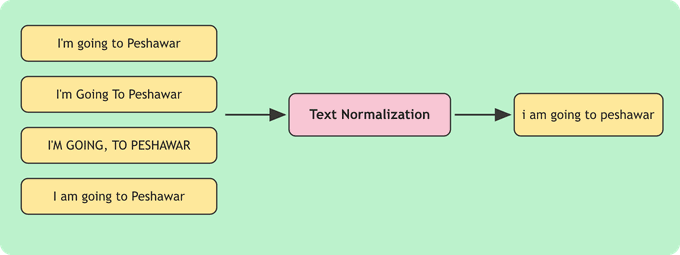
>
> ### 🔧 Los pasos principales
>
> **1. Tokenización (segmentación de palabras)**
>
> Divide el texto en unidades significativas (tokens): palabras o subpalabras.
> - Ejemplo: `"El procesamiento de texto"` → `["El", "procesamiento", "de", "texto"]`
>
> **2. Estandarización de formatos**
>
> Convierte el texto a un formato uniforme:
> - Pasar todo a minúsculas.
> - Eliminar caracteres especiales o puntuación irrelevante.
> - Sustituir palabras por variantes estándar (ej. `"décima"` → `"10ª"`).
>
> **3. Segmentación de oraciones**
>
> Identifica dónde termina una oración y empieza la siguiente.
> - Ejemplo: `"Hola. ¿Cómo estás?"` → `["Hola.", "¿Cómo estás?"]`
>
> 🧠 **Para pensar:** no hay una receta universal. Para clasificar tweets probablemente quieras conservar los emojis; para analizar artículos científicos, no. **Conocer tus datos** es lo que te dice qué normalización aplicar.
>
> 💻 **A continuación:** implementamos nuestra propia función `normalize()` y la aplicamos a todo el corpus de noticias.


In [ ]:
def normalize(text, remove_tildes=True):
    """Normaliza una cadena de texto convirtiéndo todo a minúsculas, quitando los caracteres no alfabéticos y los tildes"""
    text = text.lower()  # Llevamos todo a minúscula
    # Reemplazamos los caracteres no alfabéticos por un espacio
    text = re.sub(r'[^A-Za-zñüáéíóú]', ' ', text)
    if remove_tildes:
        text = re.sub('á', 'a', text)  # Reemplazamos los tildes
        text = re.sub('é', 'e', text)
        text = re.sub('í', 'i', text)
        text = re.sub('ó', 'o', text)
        text = re.sub('ú', 'u', text)
    return text

In [ ]:
spanish_news_normalized = spanish_news["train"].map(
    lambda x: {  # Utilizamos una función anónima que devuelve un diccionario
        # Esta es una nueva característica que agregaremos a nuestro conjunto de datos.
        "normalized_text": normalize(x["text"])
    })

In [ ]:
spanish_news_normalized

Ahora nuestro conjunto de datos cuenta con una nueva característica `normalized_text`.

In [ ]:
spanish_news_normalized[0]

### 🧪 Probando normalize() con distintos parámetros

*Práctica — ejecuta la celda y modifica el código para experimentar.*

In [ ]:
ejemplo = spanish_news["train"][10]["text"]

print("Texto original:")
print(ejemplo)
print()
print("normalize(texto, remove_tildes=True):")
print(normalize(ejemplo, remove_tildes=True))
print()
print("normalize(texto, remove_tildes=False):")
print(normalize(ejemplo, remove_tildes=False))


In [ ]:
#@title Probar `normalize()` sobre un documento
indice = 0  #@param {type:"slider", min:0, max:4999, step:1}
remove_tildes = True  #@param {type:"boolean"}

texto = spanish_news["train"][indice]["text"]
print("Original:   ", texto)
print("Normalizado:", normalize(texto, remove_tildes=remove_tildes))


## Tokenización

La tokenización es el proceso de demarcación de secciones de una cadena de caracteres. Estas secciones podrían ser oraciones, palabras o subpalabras.

El método más simple para tokenizar una cadena de caracteres en nuestro lenguaje es la separación por espacios. Aplicamos una separación por espacios mediante el método `str.split()` sobre nuestro conjunto de datos normalizado.

In [ ]:
spanish_news_normalized[0]["normalized_text"]

In [ ]:
spanish_news_normalized[0]["normalized_text"].split()

Si bien el método de separación por espacios funciona bien en nuestro conjunto de datos normalizado, también quisiéramos tokenizar nuestro texto sin normalizar.

In [ ]:
spanish_news_normalized[0]["text"]

In [ ]:
spanish_news_normalized[0]["text"].split()

Al aplicar el mismo métodos podemos observar que no funciona totalmente bien debido a la presencia de caracteres no alfabéticos. Para solucionar esto, existen métodos basados en una serie de reglas para solucionar estos problemas. Utilizaremos la implementación de un tokenizador basado en reglas de la biblioteca de procesamiento de lenguaje natural Spacy.

> ## 📘 Algoritmo de tokenización
>
> *Separar por espacios funciona... hasta que deja de funcionar.*
>
> ### 🌍 El tokenizador depende del idioma
>
> El algoritmo que usemos para tokenizar debe ser **consistente con el lenguaje que estamos analizando**: distintos idiomas usan los símbolos de manera distinta. Un tokenizador diseñado para inglés puede fallar en español (y ni hablar del chino o el japonés, donde no hay espacios entre palabras).
>
> ### 🧪 Tokenizadores basados en reglas (expresiones regulares)
>
> Una de las formas más flexibles de construir un tokenizador es **programarlo con expresiones regulares**: definimos patrones para lo que consideramos un token (una abreviación como `EE.UU.`, un monto como `$12.40`, una palabra con guión...) y el motor de regex hace el resto.
>
> - ✅ **Ventaja:** control total, determinístico, fácil de depurar.
> - ❌ **Desventaja:** hay que anticipar todos los casos. Cualquier cosa que no previste puede quedar mal tokenizada.
>
> ⚠️ **El problema de las palabras fuera de vocabulario (OOV):** estos algoritmos determinísticos funcionan bien en general, pero cuando llegue texto nuevo que no anticipamos, pueden aparecer tokens que **no están en nuestro vocabulario**. Por eso existen técnicas más modernas que *aprenden* el vocabulario a partir de los datos (las veremos enseguida).
>
> 💻 **A continuación:** probamos un tokenizador con expresiones regulares sobre una frase de noticias, y luego lo comparamos con el tokenizador basado en reglas de spaCy.


### 🧪 Tokenizando con una expresión regular (como en la teoría)

*Práctica — ejecuta la celda y modifica el código para experimentar.*

In [ ]:
texto_ejemplo = "El cartel de EE.UU. cuesta $12.40... ¡un 25% de descuento!"

# OJO: en nltk.regexp_tokenize los grupos deben ser NO capturantes (?:...),
# si no, findall devuelve los grupos en vez del token completo.
# También importa el orden: las alternativas más específicas (abreviaciones, montos)
# deben ir ANTES que \w+, que si no "se come" el número y deja "12", ".", "40".
patron = r'''(?x)                 # modo verbose: permite comentarios dentro del patrón
    (?:[A-ZÁÉÍÓÚ]+\.)+            # abreviaciones, p. ej. EE.UU.
  | \$?\d+(?:\.\d+)?%?          # montos y porcentajes, p. ej. $12.40, 25%
  | \w+(?:-\w+)*                 # palabras con guiones internos opcionales
  | \.\.\.                        # puntos suspensivos
  | [¡¿!.,;"'?():_-]             # estos símbolos quedan como tokens separados
'''

nltk.regexp_tokenize(texto_ejemplo, patron)


### 🧪 El orden de los pasos importa

*Práctica — compara las dos rutas sobre la misma frase.* Si normalizamos **antes** de tokenizar, perdemos las pistas (mayúsculas, puntos) que el tokenizador necesita para reconocer `EE.UU.`.

In [ ]:
frase = "El cartel de EE.UU. llegó a Chile"

# Ruta A: normalizar primero y luego tokenizar
ruta_a = normalize(frase).split()

# Ruta B: tokenizar con reglas primero y luego pasar a minúsculas
ruta_b = [t.lower() for t in nltk.regexp_tokenize(frase, patron)]

print("A (normalizar -> tokenizar):", ruta_a)
print("B (tokenizar -> minúsculas):", ruta_b)

### 🔤 El tokenizador de spaCy

[**spaCy**](https://spacy.io) es una biblioteca de NLP pensada para usar en aplicaciones reales. Para cada idioma ofrece *pipelines* ya entrenados que tokenizan, lematizan, etiquetan la categoría gramatical de cada palabra y reconocen entidades. El que instalamos al comienzo, `es_core_news_sm`, es el pipeline **pequeño** (*sm*) para **español** (*es*), entrenado con texto de **noticias** (*news*). Más adelante lo usaremos para lematizar.

Por ahora solo tomamos su **tokenizador** (`.tokenizer`), sin el resto del pipeline, que es mucho más lento. A diferencia de BPE o WordPiece (que veremos luego), el tokenizador de spaCy **no se entrena con datos**: aplica reglas del idioma. Primero separa el texto por espacios y después revisa cada fragmento:

| Regla | Qué revisa | Ejemplos |
|---|---|---|
| Excepción (`SPECIAL`) | ¿Es una abreviación conocida del idioma? Se deja entera. | `Sr.`, `EE.UU.` |
| Prefijo (`PREFIX`) | ¿Empieza con un signo que hay que separar? | `¿`, `¡`, `(` |
| Sufijo (`SUFFIX`) | ¿Termina con un signo que hay que separar? | `,` `.` `?` `!` `)` |
| Infijo (`INFIX`) | ¿Tiene en el medio un signo que separa dos tokens? | `perro/gato`, `hola...chao` |
| Token (`TOKEN`) | Lo que queda es un token. | `Pérez`, `10:30`, `ex-presidente` |

Las reglas y las excepciones vienen incluidas en el pipeline del español: no tenemos que escribir ninguna expresión regular.

In [ ]:
spacy_tokenizer = spacy.load("es_core_news_sm").tokenizer

In [ ]:
# explain() muestra qué regla produjo cada token
frase = "¿El Sr. Pérez, ex-presidente de EE.UU., llegó a las 10:30 a.m.?"
for regla, token in spacy_tokenizer.explain(frase):
    print(f"{token:<15} ← {regla}")

- `¿` se separa como **prefijo** y las comas y el `?` final como **sufijos**.
- `Sr.` y `EE.UU.` son **excepciones**: el punto no se separa, porque es parte de la abreviación.
- `ex-presidente` y `10:30` quedan enteros: en español, spaCy no corta en el guion ni en los dos puntos.
- `a.m.` **no** está entre las excepciones del español: queda como `a.m` + `.`. Ningún conjunto de reglas es perfecto.

Prueben con `"perro/gato"` o `"hola...chao"` para ver un **infijo**. Ahora tokenicemos la primera noticia del corpus.

In [ ]:
list(spacy_tokenizer(spanish_news_normalized[0]["text"]))

Al utilizar el tokenizador basado en reglas, podemos tener resultados mucho mejores que los anteriores.

### 🧪 Comparando tokenizadores en casos difíciles

*Práctica — ejecuta la celda y modifica el código para experimentar.*

In [ ]:
casos_dificiles = [
    "El Sr. Pérez, ex-presidente, llegó a la cumbre a las 10:30 a.m.",
    "La ONU informó que el PIB creció un 2.5% durante el T3 de 2023.",
    "¿Habrá elecciones este año? ¡Todo indica que sí!",
    "El Banco Central subió la tasa hace 3-4 semanas, según fuentes oficiales.",
]

for texto in casos_dificiles:
    print("Texto:", texto)
    print("  split():        ", texto.split())
    print("  spaCy tokenizer: ", [t.text for t in spacy_tokenizer(texto)])
    print()


> ## 📘 Tokenizadores modernos: BPE, WordPiece, SentencePiece
>
> *En vez de definir reglas a mano, dejamos que el algoritmo aprenda de los datos qué pedazos de texto son útiles.*
>
> ### 💡 La idea central: subpalabras
>
> Los tokenizadores modernos se basan en la **distribución de los símbolos en el conjunto de entrenamiento** para construir el vocabulario. Esto les permite:
>
> - Dividir el texto no solo en palabras completas, sino también en **subpalabras** o unidades más pequeñas.
> - Manejar **palabras desconocidas** combinando subpalabras que sí están en el vocabulario.
> - **Generalizar mejor** a dominios nuevos.
>
> Mira este ejemplo:
>
> ```
> La canción y la actuación, cantando y actuando ando
> La can##ción y la actua##ción , cant##ando y actu##ando ando
> ```
>
> El tokenizador descubrió solo que `##ción` y `##ando` son pedazos frecuentes y reutilizables. Nunca le enseñamos morfología española.
>
> 🧠 **Sutileza importante:** `##ando` (subpalabra, se pega a lo anterior) y `ando` (palabra completa) son **tokens distintos**. Los `##` indican "continúa la palabra anterior".
>
> ⚠️ Las subpalabras que aprende el algoritmo **no siempre son morfemas reales**. A veces coinciden con la gramática (como `-ción`), pero muchas veces son simplemente secuencias frecuentes sin significado lingüístico.
>
> ### 🏗️ Los tres algoritmos principales
>
> <table><thead><tr><th>Algoritmo</th><th>Lo usan modelos como...</th></tr></thead><tbody><tr><td><b>BPE</b> (Byte-Pair Encoding)</td><td>GPT, RoBERTa</td></tr><tr><td><b>WordPiece</b></td><td>BERT, DistilBERT</td></tr><tr><td><b>SentencePiece</b> (Google)</td><td>T5, mBERT — independiente del idioma</td></tr></tbody></table>
>
> ### ⚙️ Cómo funciona BPE (el más simple de todos)
>
> 1. Empieza con un vocabulario que contiene **todos los caracteres** presentes en el texto.
> 2. Busca el **par de símbolos adyacentes más frecuente**.
> 3. Fusiona todas las apariciones de ese par en un nuevo símbolo y lo agrega al vocabulario.
> 4. Repite `k` veces (`k` es un hiperparámetro).
>
> Al final, las palabras frecuentes quedan representadas completas, y las palabras raras quedan representadas por subpalabras.
>
> 💡 **Detalle práctico:** estos algoritmos se aplican **después** de un tokenizador simple (típicamente por espacios). Así nunca se generan subpalabras más largas que una palabra.
>
> ### 🤗 Tokenizadores y modelos preentrenados
>
> En el repositorio **Hugging Face** se distribuyen miles de modelos preentrenados, y junto con cada modelo viene **su propio tokenizador**, entrenado por los mismos investigadores. Ejemplo: el BERT en español desarrollado por el DCC de la Universidad de Chile ([dccuchile/bert-base-spanish-wwm-uncased](https://huggingface.co/dccuchile/bert-base-spanish-wwm-uncased)) usa un tokenizador tipo SentencePiece cuyo vocabulario incluye piezas como `##viste`, `tienda`, `##ple`, `mó`, `presentó`, `##gados`, `europeas`...
>
> La biblioteca `tokenizers` de 🤗 implementa todos estos algoritmos, y es la que usaremos a continuación.
>
> ### 📊 Tokens vs. Types: no confundir
>
> - **Tokens** son cada uno de los segmentos del texto, *con repeticiones*.
> - **Types** son los tokens *distintos*. El conjunto de types es el **vocabulario**.
>
> ```
> Texto:       Me gustan los lenguajes de programación y los lenguajes naturales.
> tokens     = [Me, gustan, los, lenguajes, de, programación, y, los, lenguajes, naturales, .]   ← 11 (lista)
> vocabulary = {Me, gustan, los, lenguajes, de, programación, y, naturales, .}                   ← 9 (conjunto)
> ```
>
> Fíjate: `los` y `lenguajes` aparecen dos veces en la lista de tokens, pero una sola vez en el vocabulario. El primer objeto es una **lista**; el segundo, un **conjunto** (`set`).
>
> 💻 **A continuación:** simulamos BPE paso a paso con código, y luego entrenamos un tokenizador WordPiece real sobre nuestro corpus de noticias.


### 🧪 Simulando BPE (Byte-Pair Encoding) paso a paso

*Práctica — ejecuta la celda y modifica el código para experimentar.*

In [ ]:
import collections


def bpe_pasos(texto, n_iteraciones=5):
    """Simula, paso a paso, las primeras fusiones del algoritmo BPE sobre `texto`."""
    simbolos = list(texto)
    print("Inicio:      ", simbolos)
    for i in range(n_iteraciones):
        pares = collections.Counter(zip(simbolos, simbolos[1:]))
        if not pares:
            break
        par_mas_frecuente, frecuencia = pares.most_common(1)[0]
        if frecuencia < 2:
            break
        nuevo_simbolo = "".join(par_mas_frecuente)
        nuevos_simbolos, j = [], 0
        while j < len(simbolos):
            if j < len(simbolos) - 1 and (simbolos[j], simbolos[j + 1]) == par_mas_frecuente:
                nuevos_simbolos.append(nuevo_simbolo)
                j += 2
            else:
                nuevos_simbolos.append(simbolos[j])
                j += 1
        simbolos = nuevos_simbolos
        print(f"Paso {i + 1}: fusionamos {par_mas_frecuente} (x{frecuencia}) -> {simbolos}")
    return simbolos


_ = bpe_pasos("ABABCABCD", n_iteraciones=4)


### Tokenizers

También cuenta con una biblioteca llamada Tokenizers, con la cual podemos construir nuestro tokenizador basado en nuestro conjunto de datos.

Instanciamos el tokenizador con un modelo WordPiece, el cual parte construyendo un vocabulario que incluye todas los caracteres presentes en el conjunto de datos y posteriormente comienza a mezclar caracteres hasta encontrar conjuntos de caracteres que tienen más probabilidad de aparecer juntos que separados.

In [ ]:
tokenizer = tokenizers.Tokenizer(tokenizers.models.WordPiece())

Esta biblioteca nos permite añadir pasos de normalización directamente. Replicamos lo mismo que hacemos con nuestra función `normalizer()`.

In [ ]:
normalizer = tokenizers.normalizers.Sequence([
    tokenizers.normalizers.Lowercase(),  # Llevamos todo a minúscula
    # Separamos cada caracter según los elementos que lo componen: á -> (a, ´)
    tokenizers.normalizers.NFD(),
    tokenizers.normalizers.StripAccents(),  # Eliminamos todos los acentos
    # Reemplazamos todos los caracteres no alfabéticos
    tokenizers.normalizers.Replace(tokenizers.Regex(r"[^a-z ]"), " ")
])

In [ ]:
normalizer.normalize_str(spanish_news_normalized[0]["text"])

Añadimos el normalizador al tokenizador

In [ ]:
tokenizer.normalizer = normalizer

Pre tokenizamos nuestro conjunto de datos mediante espacio para delimitar el tamaño que puede tener cada token.

In [ ]:
tokenizer.pre_tokenizer = tokenizers.pre_tokenizers.Whitespace()

Instanciamos el entrenador que entrenará nuestro tokenizador.

In [ ]:
trainer = tokenizers.trainers.WordPieceTrainer()

Entrenamos el tokenizador sobre nuestro conjunto de datos.

In [ ]:
tokenizer.train_from_iterator(spanish_news_normalized["text"], trainer)

Mediante el método `Tokenizer.encode()` obtenemos la representación tokenizada de nuesto texto. Esta representación contiene varios atributos, donde los más interesantes son:

- `ids`: Contiene nuestro texto representado a través de una lista que contiene los identificadores de cada token.
- `tokens`: Contiene nuestro texto representado a través de una lista que contiene el texto de cada token.

In [ ]:
spanish_news_normalized[0]["text"]

In [ ]:
tokenized_output = tokenizer.encode(spanish_news_normalized[0]["text"])

In [ ]:
# Para ver todo el vocabulario del tonekizador consultar la siguiente funcion
tokenizer.get_vocab()

In [ ]:
tokenized_output.ids

In [ ]:
tokenized_output.tokens

### 🧪 Efecto del tamaño de vocabulario (vocab_size) en WordPiece

Define el tamaño máximo objetivo del vocabulario que se desea generar tras el entrenamiento

In [ ]:
texto_prueba = spanish_news_normalized[0]["text"]

for vocab_size in [50, 100, 500, 1000]:
    tokenizer_experimental = tokenizers.Tokenizer(tokenizers.models.WordPiece())
    tokenizer_experimental.normalizer = normalizer
    tokenizer_experimental.pre_tokenizer = tokenizers.pre_tokenizers.Whitespace()
    trainer_experimental = tokenizers.trainers.WordPieceTrainer(vocab_size=vocab_size)
    tokenizer_experimental.train_from_iterator(spanish_news_normalized["text"], trainer_experimental)
    salida = tokenizer_experimental.encode(texto_prueba)
    print(f"vocab_size={vocab_size:5d} -> {len(salida.tokens)} tokens: {salida.tokens}")
    print()

# A menor vocab_size, el vocabulario cuenta con menos palabras completas y el texto
# se fragmenta en más subpalabras; a mayor vocab_size, más palabras quedan enteras.


Tal como lo hicimos anteriormente podemos aplicar paralelamente nuestro tokenizador sobre el conjunto de datos mediante el método `Dataset.map()`

In [ ]:
spanish_news_normalized_tokenized = spanish_news_normalized.map(
    lambda x: {"tokenized_text": tokenizer.encode(x["text"]).tokens})

Nuestro conjunto de datos ahora contiene el texto tokenizado en la característica `tokenized_text`.

In [ ]:
spanish_news_normalized_tokenized[0]

## Stemming y Lematización

heu> ## 📘 Lematización y Stemming
>
> *Dos formas de responder la misma pregunta: ¿cómo hago que "corriendo", "corrí" y "correremos" cuenten como una sola palabra?*
>
> ### 🌱 Lematización
>
> Es el proceso de reducir cada palabra a su **forma base o "lema"**, considerando el **contexto gramatical**.
>
> ```
> cantando  → cantar        gatos → gato
> canté     → cantar        gata  → gato
> correrá   → correr
> pensado   → pensar
> estrellado [verbo]    → estrellar
> estrellado [adjetivo] → estrellado
> ```
>
> Observa el último ejemplo: **la misma palabra tiene lemas distintos según su categoría gramatical**. Los verbos van al infinitivo, los plurales al singular, y "estrellado" puede ser un verbo (estrellar) o un adjetivo (estrellado). Por eso la lematización necesita **entender** algo de gramática.
>
> **¿Cómo lo hace?** Con un *analizador morfológico*: un modelo que identifica la categoría gramatical de la palabra, su significado y el contexto en que aparece. Con esa información puede llevarla correctamente a su forma canónica.
>
> ### ✂️ Stemming
>
> Es la versión **simplificada y más heuristica**: corta directamente los sufijos de las palabras para reducirlas a una raíz (*stem*), **sin análisis morfológico ni contexto**.
>
> ```
> cantando   → cant
> canté      → cant
> correrá    → corr
> pensado    → pens
> estrellado → estrell
> gatos      → gat
> ```
>
> Nota que `cant`, `corr` o `estrell` **no son palabras reales**. El stemmer no lo sabe ni le importa: solo aplica reglas de corte.
>
> Los algoritmos clásicos son el **Porter Stemmer** y el **Snowball Stemmer** (una evolución de Porter, con soporte para muchos idiomas incluido el español). La idea general es cortar las "colas" de las palabras de la manera más sistemática posible.
>
> ### ⚖️ Comparación rápida
>
> <table><thead><tr><th></th><th>Lematización</th><th>Stemming</th></tr></thead><tbody><tr><td><b>Resultado</b></td><td>Palabra real (<code>correr</code>)</td><td>Raíz, a menudo no es palabra (<code>corr</code>)</td></tr><tr><td><b>Considera contexto</b></td><td>Sí</td><td>No</td></tr><tr><td><b>Velocidad</b></td><td>Más lenta</td><td>Muy rápida</td></tr><tr><td><b>Precisión</b></td><td>Alta</td><td>Media (puede sobre-cortar)</td></tr><tr><td><b>Requiere</b></td><td>Modelo del idioma</td><td>Solo reglas</td></tr></tbody></table>
>
> 💻 **A continuación:** aplicamos ambas técnicas al mismo texto con spaCy (lematización) y NLTK (stemming), y comparamos los resultados palabra por palabra.


Para reducir el vocabulario usaremos **lematización** (spaCy) y **stemming** (NLTK, algoritmo Snowball). Ambos operan sobre palabras completas, por eso usamos el tokenizador propio de spaCy y no las subpalabras de WordPiece.

Instanciamos el analizador de spaCy (con su tokenizador basado en reglas, que respeta palabras completas)

In [ ]:
nlp = spacy.load("es_core_news_sm")

Instanciamos el Stemmer

In [ ]:
stemmer = nltk.stem.SnowballStemmer("spanish")

Podemos verificar cómo funcionan estos métodos sobre un texto de prueba de nuestro conjunto de datos.

In [ ]:
spanish_news_normalized_tokenized[5]["text"]

In [ ]:
texto = spanish_news_normalized_tokenized[5]["text"]
# Usamos el texto original (con tildes y mayúsculas): el lematizador necesita esa información
for t in list(nlp(texto))[:40]:
    print(f"Token: {t.text:15s} POS: {t.pos_:6s} Lema: {t.lemma_:15s} Stem: {stemmer.stem(t.text)}")


### 🧪 Lematización y stemming con tus propias palabras

*Práctica — ejecuta la celda y modifica el código para experimentar.*

In [ ]:
palabras_prueba = [
    "corriendo", "corrimos", "correrán",
    "estudiando", "estudié", "estudiantes",
    "felices", "felizmente",
]

for palabra in palabras_prueba:
    doc = nlp(palabra)
    lema = doc[0].lemma_ if len(doc) > 0 else palabra
    stem = stemmer.stem(palabra)
    print(f"{palabra:15s} -> lema: {lema:15s} | stem: {stem}")


In [ ]:
#@title Compara lema y stem de una palabra
palabra = "corriendo"  #@param {type:"string"}

doc = nlp(palabra)
lema = doc[0].lemma_ if len(doc) > 0 else palabra
stem = stemmer.stem(palabra)
print(f"Lema: {lema}")
print(f"Stem: {stem}")


> ## 📘 ¿Cuándo usar stemming o lematización?
>
> *Reducir el vocabulario tiene ventajas claras... pero ya no siempre es necesario.*
>
> ### ✅ Por qué querríamos reducir el tamaño del vocabulario
>
> - **Visualización:** facilita el análisis exploratorio; una nube de palabras con "corriendo", "corrí" y "correremos" separadas es más confusa que una con solo "correr".
> - **Generalización:** mejora el rendimiento de los modelos al evitar sobreajustes a variantes raras.
> - **Eficiencia:** menos vocabulario = menos parámetros = menos cómputo.
> - **Menos palabras fuera de vocabulario (OOV):** al agrupar variantes, es más probable que la forma canónica sí esté en nuestro vocabulario.
>
> ### 🤖 ...pero los modelos modernos ya lo resuelven de otra forma
>
> Los modelos de lenguaje actuales usan **tokenización por subpalabras** (BPE, WordPiece...), lo que **reduce naturalmente el vocabulario y mitiga el problema OOV** sin necesidad de lematizar ni hacer stemming. Si vas a usar BERT o GPT, casi nunca necesitas estos pasos.
>
> ### 🎯 ¿Entonces cuándo sí?
>
> La lematización o el stemming **siguen siendo muy útiles** en:
>
> - **Tareas clásicas** (búsqueda, conteo de palabras, clustering, TF-IDF).
> - **Procesos interpretativos o explicativos**, donde una persona va a leer el resultado y quiere ver palabras reales.
> - **Modelos pequeños o específicos de dominio** con datos limitados, donde cada reducción de vocabulario ayuda.
>
> 💡 **Consejo:** si usas stemming para una visualización, ten en cuenta que aparecerán pedazos de palabras que pueden ser difíciles de interpretar (`cant`, `estrell`). Para nubes de palabras suele verse mejor la lematización.


> ## 📘 Errores comunes en preprocesamiento (¡no los cometas!)
>
> *Estos son los errores que vemos una y otra vez. Cada uno parece inofensivo hasta que te arruina el modelo.*
>
> ### ❌ 1. Preprocesar el conjunto de test distinto al de train
> Si entrenaste con texto en minúsculas sin tildes, el test **tiene que** pasar por exactamente el mismo pipeline. Si no, el modelo verá tokens que nunca conoció y su rendimiento se derrumba... y tú no entenderás por qué.
>
> ### ❌ 2. Eliminar stopwords sin mirar el contexto
> ```
> "No me gusta"  →  (quitamos "no" y "me")  →  "gusta"
> ```
> ¡Acabas de invertir el sentimiento de la frase! Las stopwords son irrelevantes *en general*, pero en tareas como análisis de sentimiento las negaciones son críticas.
>
> ### ❌ 3. Tokenizar después de pasar a minúsculas
> ```
> "U.S.A."  →  "u.s.a."  →  ["u", "s", "a"]
> ```
> El tokenizador ya no reconoce la abreviación porque perdió las mayúsculas que la identificaban. **El orden de los pasos importa.**
>
> ### ❌ 4. No manejar el encoding correctamente
> Mezclar UTF-8 con Latin-1 produce caracteres extraños (`Ã±` en vez de `ñ`, `Ã©` en vez de `é`). Parece un detalle menor, pero te genera tokens basura que contaminan todo el vocabulario.
>
> ### ❌ 5. Sobre-stemming sin validar
> ```
> "university"  →  "univers"
> "universe"    →  "univers"
> ```
> Dos palabras con significados distintos colapsan en la misma raíz. Siempre revisa una muestra de lo que produce tu stemmer antes de confiar en él.
>
> 🧠 **Regla de oro:** después de cada paso de preprocesamiento, **mira una muestra del resultado**. Cinco minutos de inspección visual te ahorran horas de depuración.


## ✍️ Ejercicios

*Ahora te toca a ti. Intenta cada uno antes de abrir la solución.*

### ✍️ Ejercicio 1

Escribe `normalize_v2` que **conserve los números y los signos `¿?¡!`** (útiles en análisis de sentimiento), pero siga pasando a minúsculas y quitando tildes.

💡 *Pista:* modifica la clase de caracteres de `re.sub`.

<details><summary>👀 Ver solución (inténtalo primero)</summary>

```python
def normalize_v2(text, remove_tildes=True):
    text = text.lower()
    text = re.sub(r"[^a-z0-9ñüáéíóú¿?¡! ]", " ", text)   # conservamos dígitos y signos de énfasis
    if remove_tildes:
        for a, b in zip("áéíóú", "aeiou"):
            text = text.replace(a, b)
    return text

normalize_v2("¡Subió 25% el dólar en 2023!")
```

</details>

### ✍️ Ejercicio 2

Extiende el patrón del tokenizador para que reconozca **menciones y hashtags** (`@andres`, `#NLP`) como un solo token.

💡 *Pista:* agrega una alternativa `[@#]\w+` **antes** de `\w+`.

<details><summary>👀 Ver solución (inténtalo primero)</summary>

```python
patron_redes = r"""(?x)
    [@#]\w+                 # menciones y hashtags
  | (?:[A-ZÁÉÍÓÚ]+\.)+
  | \$?\d+(?:\.\d+)?%?
  | \w+(?:-\w+)*
  | [¡¿!.,;?():]
"""
nltk.regexp_tokenize("@andres dice que #NLP cuesta $12.40 :)", patron_redes)
```

</details>

### ✍️ Ejercicio 3

Elige 4 palabras de tu propio dominio y compara lema vs. stem. ¿En cuáles el stemmer produce algo que no es una palabra real? ¿En cuáles el lematizador se equivoca?

💡 *Pista:* reutiliza `nlp` y `stemmer`.

<details><summary>👀 Ver solución (inténtalo primero)</summary>

```python
mis_palabras = ["jugando", "jugadores", "juguetón", "abogados"]
for p in mis_palabras:
    print(f"{p:12s} lema: {nlp(p)[0].lemma_:12s} stem: {stemmer.stem(p)}")
```

</details>